# Exploratory data analysis of the O'FAIRe scores

This notebook explores the scores of the EarthPortal **artefacts** (views and metadata-only records are
left out). It follows four steps:

- **I.** Loading the scores
- **II.** Where the catalogue loses points
- **III.** Profiling report
- **IV.** Some plots informed by the profiling report

In [1]:
# Imports
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from data_profiling import ProfileReport      # successor of ydata-profiling

from config import *

# I. Loading the scores

In [2]:
scores = pd.read_csv(DATA / f"ofaire_scores_{RUN_DATE}.csv")
questions = pd.read_csv(DATA / f"ofaire_questions_{RUN_DATE}.csv")

# We keep the artefacts, and the questions an EarthPortal artefact can really score on
artefacts = scores[scores.kind == "artefact"].set_index("acronym")
kept = questions[questions.evaluable & questions.reachable].question.tolist()
print(f"{len(artefacts)} artefacts and {len(kept)} questions kept "
      f"({len(questions) - len(kept)} questions no EarthPortal artefact can score on)")
artefacts[["name", "normalized_score", "total_points", "reachable_score_pct"]].head()

68 artefacts and 49 questions kept (12 questions no EarthPortal artefact can score on)


,name,normalized_score,total_points,reachable_score_pct
acronym,,,,
OSO,Observatories of the Seas Ontology,76,364.36,94.4
NVS_OD1,ODATIS aggregation parameters and Essential Va...,61,292.75,75.8
EASY_DATA_VOCAB,EaSy Data Unified Thesaurus,60,288.00,74.6
NVS_P06,Governance for vocabularies used within the da...,60,287.75,74.5
NVS_P07,Climate and Forecast Standard Names,60,287.75,74.5


# II. Where the catalogue loses points

In [3]:
# For each question, we sum the points that all artefacts lose on it
q = questions.set_index("question").loc[kept]
summary = pd.DataFrame({
    "principle": q.principle,
    "max_credits": q.max_credits,
    "mean_pct_of_max": (100 * artefacts[kept].mean() / q.max_credits).round(1),
    "artefacts_with_zero": (artefacts[kept] == 0).sum(),
    "points_lost_by_catalogue": (q.max_credits - artefacts[kept]).sum(),
    "text": q.text,
}).sort_values("points_lost_by_catalogue", ascending=False)
summary.head(10)

,principle,max_credits,mean_pct_of_max,artefacts_with_zero,points_lost_by_catalogue,text
F1Q2,Findable,11.0,4.4,65,715.0,"Does the ontology provide an additional ""exter..."
F4Q2,Findable,10.0,11.5,32,602.0,Is the ontology registered in multiple open on...
R1.3Q1,Reusable,10.0,19.1,50,550.0,Does an ontology provide information about pro...
F1Q4,Findable,9.0,11.6,59,541.0,Does the ontology provide a version-specific U...
R1.1Q3,Reusable,15.0,51.4,0,496.0,Are the ontology usage guidelines and copyrigh...
R1.2Q2,Reusable,6.0,8.3,54,374.0,Does an ontology provide information on its ge...
R1.2Q1,Reusable,8.0,34.6,19,356.0,Does the ontology provide information about th...
A1Q4,Accessible,6.0,13.2,59,354.0,Are the ontology and its metadata accessible t...
R1.2Q6,Reusable,6.0,13.2,51,354.0,Are the methodology and tools used to build th...
R1.2Q3,Reusable,6.0,15.7,44,344.0,Are the accrual methods and policy of the onto...


**Conclusion**: the first rows of this table are where curation pays most. Notebook 04 links each
question to the metadata fields it reads, and to the corresponding entry of the cheatsheet.

# III. Profiling report

In [4]:
table = artefacts[["normalized_score", "total_points", "reachable_score_pct"] + kept].copy()
profile = ProfileReport(table, title=f"O'FAIRe scores of the EarthPortal artefacts ({RUN_DATE})", explorative=True)
path_to_report = REPORTS / f"eda_{RUN_DATE}.html"
profile.to_file(path_to_report)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 52/52 [00:00<00:00, 243.32it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [5]:
profile

# IV. Some plots informed by the profiling report

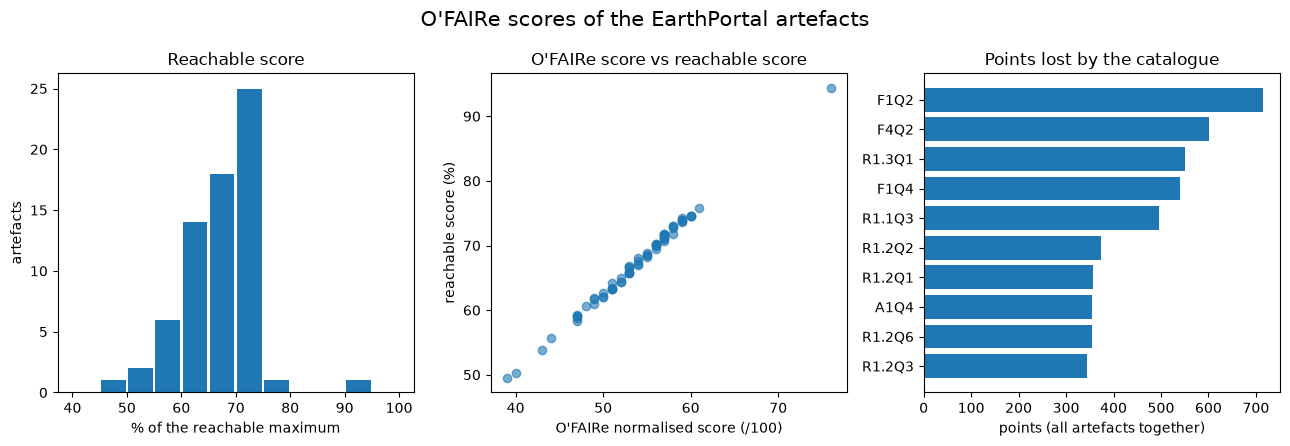

In [6]:
plt.figure(figsize=(13, 4.5))
plt.suptitle("O'FAIRe scores of the EarthPortal artefacts", fontsize=15)

# Subfig 1: how the reachable score is distributed
plt.subplot(1, 3, 1)
plt.hist(artefacts.reachable_score_pct, bins=range(40, 101, 5), rwidth=0.9)
plt.title("Reachable score")
plt.xlabel("% of the reachable maximum")
plt.ylabel("artefacts")

# Subfig 2: O'FAIRe's own score against the reachable score
plt.subplot(1, 3, 2)
plt.scatter(artefacts.normalized_score, artefacts.reachable_score_pct, alpha=0.6)
plt.title("O'FAIRe score vs reachable score")
plt.xlabel("O'FAIRe normalised score (/100)")
plt.ylabel("reachable score (%)")

# Subfig 3: the ten questions where the catalogue loses most points
plt.subplot(1, 3, 3)
top = summary.head(10).iloc[::-1]
plt.barh(top.index, top.points_lost_by_catalogue)
plt.title("Points lost by the catalogue")
plt.xlabel("points (all artefacts together)")

plt.tight_layout()
plt.show()

In [7]:
# We save the question summary for notebook 04 and for the report
summary.to_csv(DATA / f"question_summary_{RUN_DATE}.csv")
print(f"Saved {(DATA / f'question_summary_{RUN_DATE}.csv').relative_to(REPO)} and {path_to_report.relative_to(REPO)}")

Saved earthportal_sa_audit/data/question_summary_2026-10-16.csv and earthportal_sa_audit/reports/eda_2026-10-16.html
